# Week 4 matchup calls (Mon Oct 19 to Sun Oct 25)

Part 1 grades last week's predictions (Week 3, a late-start Tue-Sun window). Part 2 predicts Week 4 across all three leagues using model v1, unchanged since Week 1 and frozen through Week 6. Predictions and the three headline picks were committed before the games.

In [1]:
!rm -f data_pull.py data_pull.py.* scoring.py scoring.py.* stats.py stats.py.* matchup.py matchup.py.*
!wget -q -O data_pull.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/data_pull.py
!wget -q -O scoring.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/scoring.py
!wget -q -O stats.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/stats.py
!wget -q -O matchup.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/matchup.py

!mkdir -p predictions
!wget -q -O predictions/week03.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week03.csv

from data_pull import get_player_id, get_game_log, get_games_in_window #type: ignore
from scoring import SKATER_FIELD_MAP, GOALIE_FIELD_MAP #type: ignore
from stats import get_player_estimates, get_prior_season_stats, _scored_game_log #type: ignore
from matchup import compare_players, compare_weekly #type: ignore

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Week 3 Recap

In [2]:
SEASON = "20262027"
PRIOR_SEASON = "20252026"

# Week 3 (being graded): late start, Tuesday to Sunday only
WEEK3 = {lg: ("2026-10-13", "2026-10-18") for lg in ("league_1", "league_2", "league_3")}

# Week 4 (being predicted): full Monday to Sunday
WEEK4 = {lg: ("2026-10-19", "2026-10-25") for lg in ("league_1", "league_2", "league_3")}

league_scoring = {
    "league_1": {
        "skater": {"G": 2, "A": 1, "PIM": -0.25, "PPG": 0.5, "SHG": 2, "SHA": 1, "GWG": 1, "SOG": 0.1, "HIT": 0.25, "BLK": 0.25},
        "goalie": {"W": 5, "GA": -1, "SV": 0.1, "SHO": 5},
    },
    "league_2": {
        "skater": {"G": 2.5, "A": 1.5, "PIM": -0.25, "PPG": 0.5, "PPA": 0.25, "SHG": 1, "SHA": 0.5, "GWG": 1, "SOG": 0.1, "HIT": 0.4, "BLK": 0.5},
        "goalie": {"W": 5, "GA": -1, "SV": 0.15, "SHO": 5},
    },
    "league_3": {
        "skater": {"G": 2.55, "A": 2.37, "PPP": 1.77, "SHP": 1.73, "GWG": 3.0, "SOG": 0.1, "HIT": 0.2, "BLK": 0.15},
        "goalie": {"W": 3.85, "GA": -0.05, "SV": 0.03, "SHO": 5.75},
    },
}

SLEEPERS_W3 = ["Devon Levi", "Trevor Connelly", "Shane Pinto"]   # graded in Part 1
SLEEPER_POSITION = {"Devon Levi": "G"}

_id_cache = {}
def resolve_id(player):
    if isinstance(player, (int, np.integer)):
        return int(player)
    if player not in _id_cache:
        _id_cache[player] = get_player_id(player)
    return _id_cache[player]

def cfg_and_map(league, position):
    side = "goalie" if position == "G" else "skater"
    return league_scoring[league][side], (GOALIE_FIELD_MAP if position == "G" else SKATER_FIELD_MAP)

In [3]:
w3 = pd.read_csv("predictions/week03.csv")
print(w3.shape)
print(w3["league"].value_counts().to_dict())
print(w3["prediction_unit"].dropna().unique(), int(w3["headline_pick"].notna().sum()), "headline picks")
print("late_start:", w3["late_start"].dropna().unique(), "| window:", w3["window_start"].dropna().unique(), w3["window_end"].dropna().unique())
print("Week 4 window:", WEEK4["league_1"])


(45, 30)
{'league_3': 18, 'league_2': 14, 'league_1': 13}
['weekly_total'] 3 headline picks
late_start: [ True] | window: ['2026-10-13'] ['2026-10-18']
Week 4 window: ('2026-10-19', '2026-10-25')


In [4]:
def window_stats(player, position, league, start, end):
    """Games and total fantasy points for one player in a date window, under one league's scoring."""
    pid = resolve_id(player)
    cfg, fmap = cfg_and_map(league, position)
    log = _scored_game_log(pid, SEASON, position, cfg, fmap, force_refresh=True)
    if log is None:
        return {"games": 0, "total": 0.0}
    d = log[(log["gameDate"] >= pd.Timestamp(start)) & (log["gameDate"] <= pd.Timestamp(end))]
    return {"games": len(d), "total": float(d["fantasy_points"].sum())}

def outcome(a, b):
    return 1.0 if a > b else (0.0 if a < b else 0.5)

week3 = pd.read_csv("predictions/week03.csv")
week3_scored = week3[week3["p_me_outperforms"].notna()].copy()

rows = []
for _, r in week3_scored.iterrows():
    start, end = WEEK3[r["league"]]
    me = window_stats(r["me"], r["position"], r["league"], start, end)
    opp = window_stats(r["opponent"], r["position"], r["league"], start, end)
    rows.append({**r.to_dict(),
                 "me_games_actual": me["games"], "opp_games_actual": opp["games"],
                 "me_total": me["total"], "opp_total": opp["total"],
                 "result": outcome(me["total"], opp["total"])})

recap3 = pd.DataFrame(rows)
fav_me = recap3["favored"] == "me"
recap3["pick_won"] = np.where(fav_me, recap3["result"], 1 - recap3["result"])
recap3["brier"] = (recap3["p_me_outperforms"] - recap3["result"]) ** 2
recap3["confidence"] = np.maximum(recap3["p_me_outperforms"], 1 - recap3["p_me_outperforms"])

recap3.to_csv("predictions/week03_results.csv", index=False)
print(f"Scored {len(recap3)} Week 3 matchups")
print("Games predicted vs actual (mismatches):")
mm = recap3[(recap3["me_games"] != recap3["me_games_actual"]) | (recap3["opp_games"] != recap3["opp_games_actual"])]
print(mm[["league", "me", "opponent", "me_games", "me_games_actual", "opp_games", "opp_games_actual"]].to_string(index=False) if len(mm) else "none, all game counts matched")

Matched 'Connor McDavid' to 'Connor McDavid'
Pulling fresh game log for 8478402, 20262027
Matched 'Nathan Mackinnon' to 'Nathan MacKinnon'
Pulling fresh game log for 8477492, 20262027
Matched 'Tim Stutzle' to 'Tim Stützle'
Pulling fresh game log for 8482116, 20262027
Matched 'Fraser Minten' to 'Fraser Minten'
Pulling fresh game log for 8483489, 20262027
Matched 'Filip Forsberg' to 'Filip Forsberg'
Pulling fresh game log for 8476887, 20262027
Matched 'Pavel Dorofeyev' to 'Pavel Dorofeyev'
Pulling fresh game log for 8481604, 20262027
Matched 'Kyle Connor' to 'Kyle Connor'
Pulling fresh game log for 8478398, 20262027
Matched 'Juraj Slafkovsky' to 'Juraj Slafkovský'
Pulling fresh game log for 8483515, 20262027
Matched 'Cole Perfetti' to 'Cole Perfetti'
Pulling fresh game log for 8482149, 20262027
Matched 'Logan Stankoven' to 'Logan Stankoven'
Pulling fresh game log for 8482702, 20262027
Matched 'Alex Tuch' to 'Alex Tuch'
Pulling fresh game log for 8477949, 20262027
Matched 'Connor Bedard' 

In [5]:
n = len(recap3)
print(f"Picks won: {recap3['pick_won'].sum():.1f} of {n} ({recap3['pick_won'].mean():.1%}), Brier {recap3['brier'].mean():.3f}")
print("Brier reference: 0.250 = always 50%.\n")

print("By league:")
print(recap3.groupby("league").agg(n=("pick_won","size"), won=("pick_won","sum"),
      hit_rate=("pick_won","mean"), brier=("brier","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

recap3["bucket10"] = pd.cut(recap3["confidence"], [0.5,0.6,0.7,0.8,1.01], right=False,
                            labels=["50-60%","60-70%","70-80%","80%+"])
print("\nCalibration (10-point buckets):")
print(recap3.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
      avg_conf=("confidence","mean"), hit_rate=("pick_won","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

uneq_pred = recap3["me_games"] != recap3["opp_games"]
print("\nUnequal games (predicted):", f"{recap3[uneq_pred]['pick_won'].sum():.1f} of {uneq_pred.sum()}")
print("Equal games (predicted):  ", f"{recap3[~uneq_pred]['pick_won'].sum():.1f} of {(~uneq_pred).sum()}")


Picks won: 30.0 of 45 (66.7%), Brier 0.200
Brier reference: 0.250 = always 50%.

By league:
           n    won  hit_rate  brier
league                              
league_1  13 10.000     0.769  0.210
league_2  14  8.000     0.571  0.200
league_3  18 12.000     0.667  0.192

Calibration (10-point buckets):
           n   won  avg_conf  hit_rate
bucket10                              
50-60%    15 8.000     0.546     0.533
60-70%    15 8.000     0.661     0.533
70-80%     8 8.000     0.754     1.000
80%+       7 6.000     0.833     0.857

Unequal games (predicted): 2.0 of 2
Equal games (predicted):   28.0 of 43


In [6]:
cols = ["league","position","me","opponent","confidence","me_games_actual","opp_games_actual","me_total","opp_total","pick_won"]
print("Headline picks:")
print(recap3[recap3["headline_pick"].notna()].sort_values("headline_pick")[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

print("\nGoalie slots (expected games = team games x start share, vs actual appearances):")
g = recap3[recap3["position"] == "G"].copy()
g["me_exp"] = g["me_games"] * g["me_start_share"]
g["opp_exp"] = g["opp_games"] * g["opp_start_share"]
print(g[["league","me","me_exp","me_games_actual","opponent","opp_exp","opp_games_actual","me_total","opp_total","pick_won"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\nAll goalies: {int(g['me_games_actual'].sum() + g['opp_games_actual'].sum())} appearances vs {g['me_exp'].sum() + g['opp_exp'].sum():.1f} expected")

print("\nBiggest misses (largest Brier):")
print(recap3.sort_values("brier", ascending=False).head(5)[["league","position","me","opponent","p_me_outperforms","me_total","opp_total","me_games_actual","opp_games_actual"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

pts = pd.concat([
    recap3[["position","me","me_week_mu","me_total"]].set_axis(["position","player","pred","actual"], axis=1),
    recap3[["position","opponent","opp_week_mu","opp_total"]].set_axis(["position","player","pred","actual"], axis=1),
])
pts["err"] = pts["actual"] - pts["pred"]
print(f"\nMean expected {pts['pred'].mean():.2f}, mean actual {pts['actual'].mean():.2f}")
print(f"Correlation expected vs actual: {pts['pred'].corr(pts['actual']):.2f}")
print(pts.groupby(pts['position'].eq('G').map({True:'Goalies', False:'Skaters'}))["err"].agg(["size","mean"]).round(2))


Headline picks:
  league position                me         opponent  confidence  me_games_actual  opp_games_actual  me_total  opp_total  pick_won
league_1        C       Tim Stutzle    Fraser Minten        0.85                3                 3      4.90       7.80      0.00
league_2        C     Sebastian Aho    Brayden Point        0.81                3                 3      5.80       5.00      1.00
league_3        D Mikhail Sergachev Mackenzie Weegar        0.78                3                 3     10.00       9.45      1.00

Goalie slots (expected games = team games x start share, vs actual appearances):
  league                  me  me_exp  me_games_actual         opponent  opp_exp  opp_games_actual  me_total  opp_total  pick_won
league_1      Jeremy Swayman    1.98                2     Lukas Dostal     1.34                 2     12.00      -2.00      1.00
league_1      Jake Oettinger    1.98                2 Yaroslav Askarov     1.72                 1     11.10      -3.00  

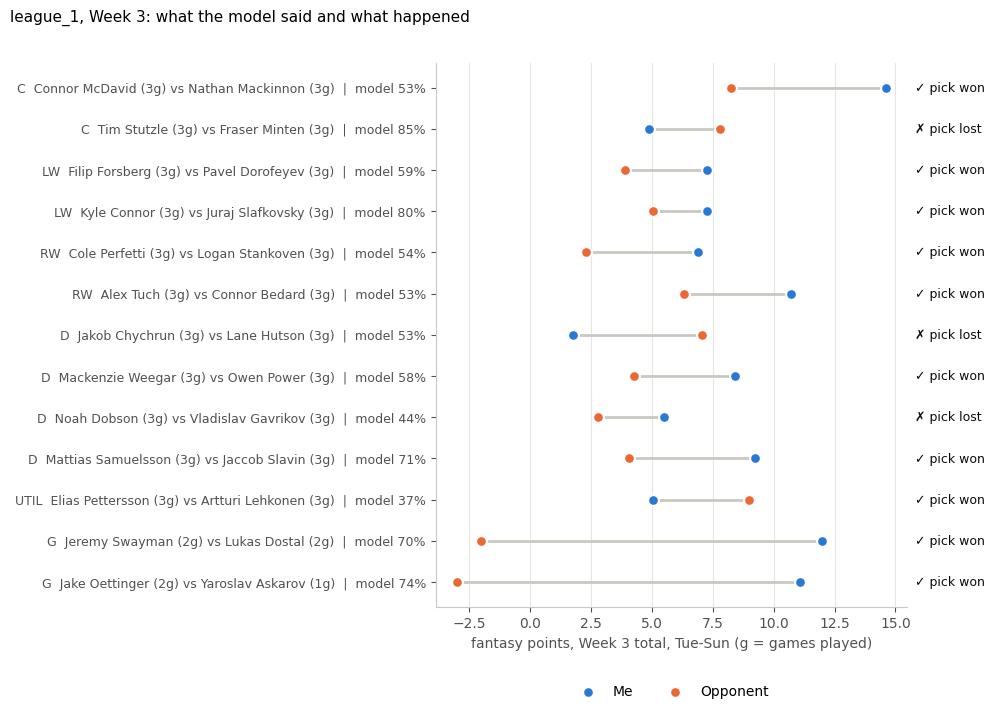

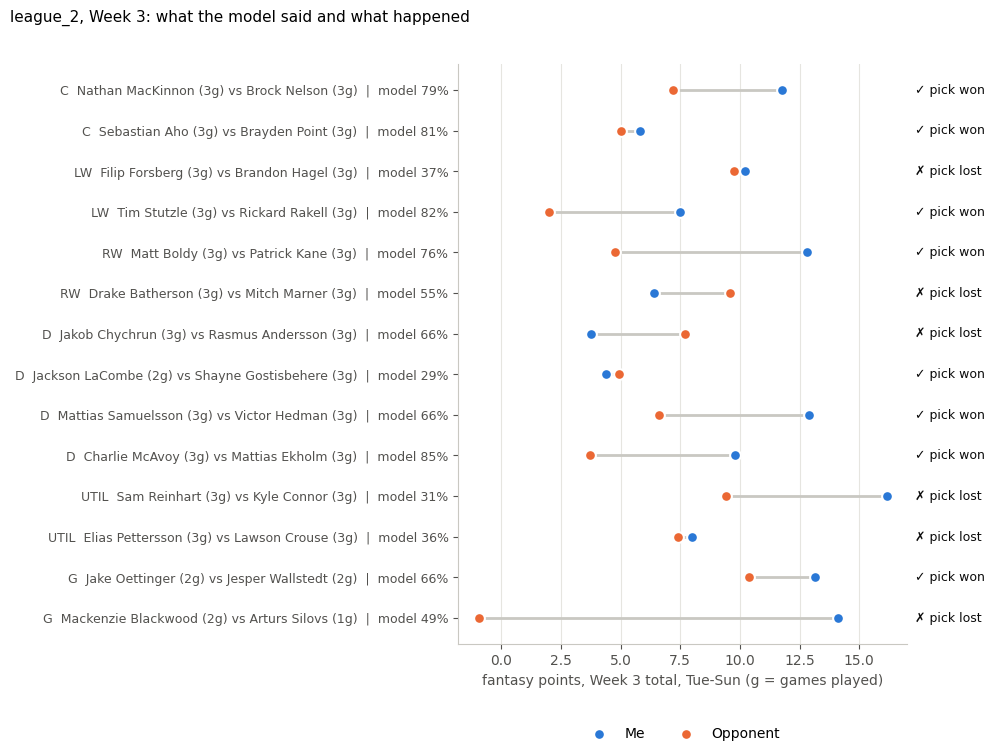

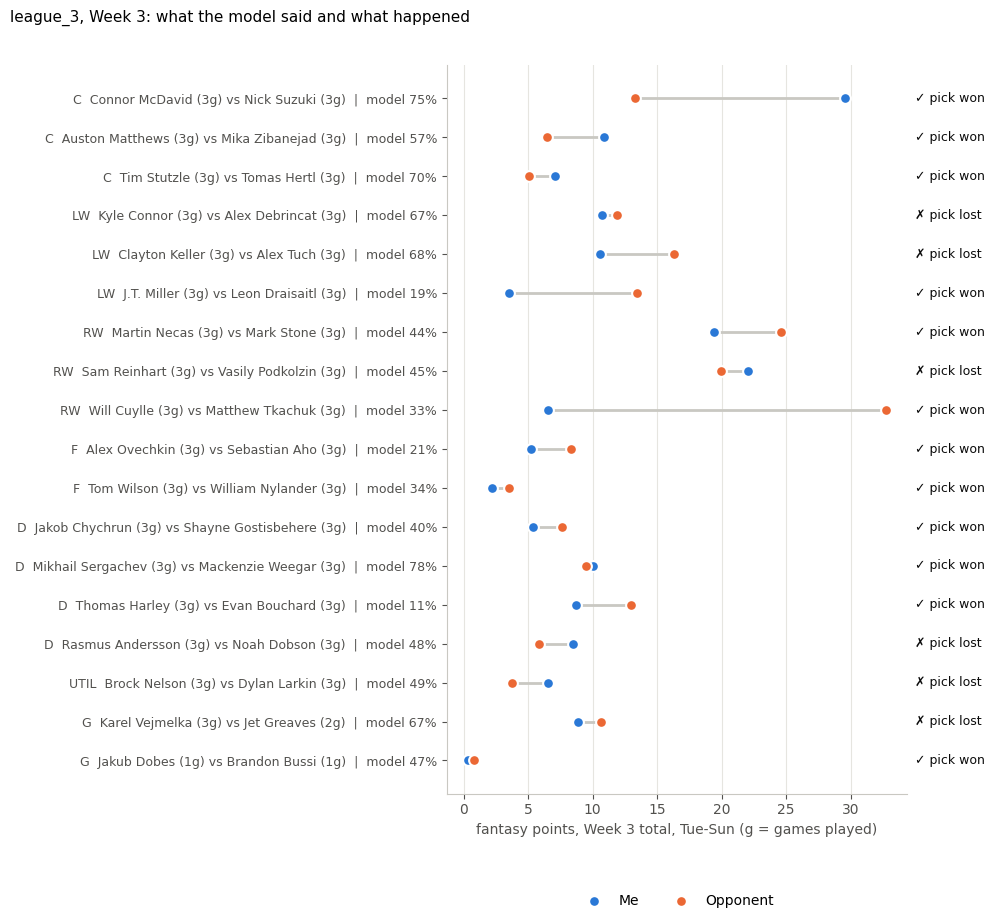

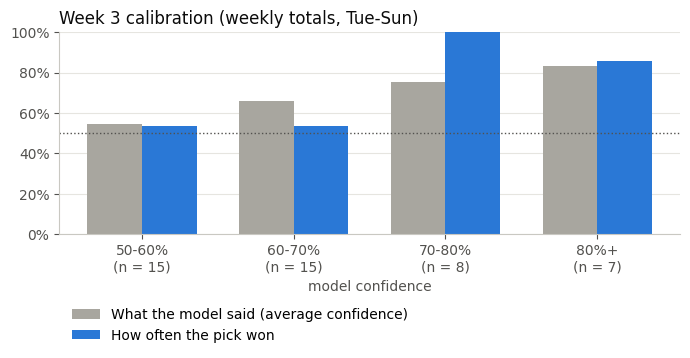

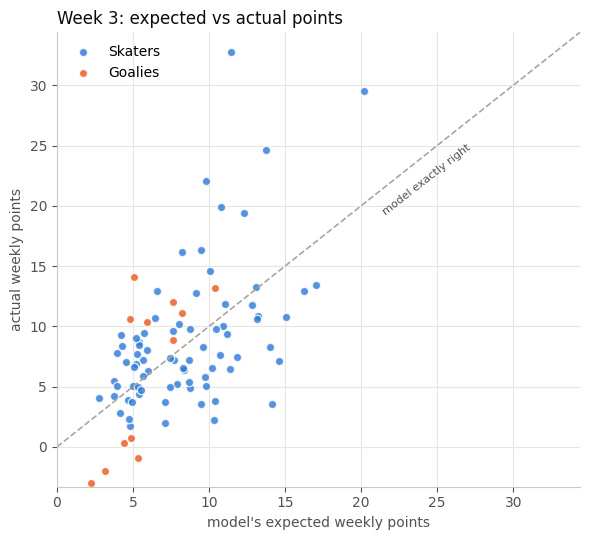

In [7]:
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#a8a69f", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

def plot_week3_matchups(league):
    d = recap3[recap3["league"] == league].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    for yi, r in zip(y, d.itertuples()):
        ax.plot([r.me_total, r.opp_total], [yi, yi], color="#c9c8c2", linewidth=2, zorder=1)
    ax.scatter(d["me_total"], y, s=60, color=BLUE, zorder=3, label="Me", edgecolor="white", linewidth=1.5)
    ax.scatter(d["opp_total"], y, s=60, color=ORANGE, zorder=3, label="Opponent", edgecolor="white", linewidth=1.5)
    labels = [f"{r.position}  {r.me} ({r.me_games_actual}g) vs {r.opponent} ({r.opp_games_actual}g)  |  model {r.p_me_outperforms:.0%}"
              for r in d.itertuples()]
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
    right = ax.get_xlim()[1]
    for yi, r in zip(y, d.itertuples()):
        sym, txt = ("✓", "pick won") if r.pick_won == 1 else (("=", "tie") if r.pick_won == 0.5 else ("✗", "pick lost"))
        ax.text(right, yi, f"  {sym} {txt}", va="center", fontsize=9, color=INK, clip_on=False)
    ax.set_xlabel("fantasy points, Week 3 total, Tue-Sun (g = games played)")
    fig.suptitle(f"{league}, Week 3: what the model said and what happened", x=0.01, ha="left", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, ncol=2)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

for lg in sorted(recap3["league"].unique()):
    plot_week3_matchups(lg)

cal = recap3.groupby("bucket10", observed=False).agg(n=("pick_won","size"),
      avg_conf=("confidence","mean"), hit=("pick_won","mean")).reset_index()
cal = cal[cal["n"] > 0]
x = np.arange(len(cal)); w = 0.36
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, cal["avg_conf"], w, color=GRAY, label="What the model said (average confidence)")
ax.bar(x + w/2, cal["hit"], w, color=BLUE, label="How often the pick won")
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle=":")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n = {n})" for b, n in zip(cal["bucket10"].astype(str), cal["n"])])
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("model confidence"); ax.set_title("Week 3 calibration (weekly totals, Tue-Sun)", loc="left")
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, -0.3))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5.5))
sk, gl = pts[pts["position"] != "G"], pts[pts["position"] == "G"]
ax.scatter(sk["pred"], sk["actual"], s=36, color=BLUE, alpha=0.8, edgecolor="white", label="Skaters")
ax.scatter(gl["pred"], gl["actual"], s=36, color=ORANGE, alpha=0.9, edgecolor="white", label="Goalies")
lim = max(pts["pred"].max(), pts["actual"].max()) * 1.05
ax.plot([0, lim], [0, lim], color=GRAY, linewidth=1.2, linestyle="--")
ax.text(lim*0.62, lim*0.56, "model exactly right", color=MUTED, fontsize=8, rotation=38)
ax.set_xlim(0, lim); ax.set_ylim(min(0, pts["actual"].min()) * 1.1, lim)
ax.set_xlabel("model's expected weekly points"); ax.set_ylabel("actual weekly points")
ax.set_title("Week 3: expected vs actual points", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

In [8]:
def scoreboard_block_w3():
    n, won = len(recap3), recap3["pick_won"].sum()
    eq = recap3["me_games"] == recap3["opp_games"]
    lines = [
        "**Week 3 results (weekly-total probabilities, Tue-Sun window)**", "",
        f"- All matchups: {won:.1f} of {n} picks won ({won/n:.1%}), Brier {recap3['brier'].mean():.3f}",
        f"- Unequal games: {recap3[~eq]['pick_won'].sum():.1f} of {(~eq).sum()}",
        f"- Equal games: {recap3[eq]['pick_won'].sum():.1f} of {eq.sum()}",
        "", "| Confidence | n | Won | Avg confidence | Hit rate |", "|---|---|---|---|---|",
    ]
    t = recap3.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
            avg=("confidence","mean"), hit=("pick_won","mean"))
    for label, r in t.iterrows():
        if r["n"]:
            lines.append(f"| {label} | {int(r['n'])} | {r['won']:.0f} | {r['avg']:.1%} | {r['hit']:.1%} |")
    lines += ["", "Brier reference: 0.250 = always 50%."]
    return "\n".join(lines)

print(scoreboard_block_w3())

# Running record across the weekly-total weeks (Week 2 + Week 3)
!wget -q -O predictions/week02_results.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week02_results.csv
try:
    r2 = pd.read_csv("predictions/week02_results.csv")
    both = pd.concat([r2.assign(week=2), recap3.assign(week=3)], ignore_index=True)
    both["bucket10"] = pd.cut(both["confidence"], [0.5,0.6,0.7,0.8,1.01], right=False, labels=["50-60%","60-70%","70-80%","80%+"])
    eqb = both["me_games"] == both["opp_games"]
    print(f"\nWeeks 2+3: {both['pick_won'].sum():.1f} of {len(both)} ({both['pick_won'].mean():.1%}), Brier {both['brier'].mean():.3f}")
    print(f"  equal games:   {both[eqb]['pick_won'].sum():.1f} of {eqb.sum()}")
    print(f"  unequal games: {both[~eqb]['pick_won'].sum():.1f} of {(~eqb).sum()}")
    print(both.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"), hit=("pick_won","mean")).to_string(float_format=lambda v: f"{v:.3f}"))
except Exception as e:
    print("Running record skipped:", e)

**Week 3 results (weekly-total probabilities, Tue-Sun window)**

- All matchups: 30.0 of 45 picks won (66.7%), Brier 0.200
- Unequal games: 2.0 of 2
- Equal games: 28.0 of 43

| Confidence | n | Won | Avg confidence | Hit rate |
|---|---|---|---|---|
| 50-60% | 15 | 8 | 54.6% | 53.3% |
| 60-70% | 15 | 8 | 66.1% | 53.3% |
| 70-80% | 8 | 8 | 75.4% | 100.0% |
| 80%+ | 7 | 6 | 83.3% | 85.7% |

Brier reference: 0.250 = always 50%.
Running record skipped: No columns to parse from file


**What I take from Week 3:**
- 30 of 45 picks won (66.7%), Brier 0.200, well ahead of a coin flip (0.250). League 1 went 10 of 13, league 2 8 of 14, league 3 12 of 18.
- I expected a near coin flip, because only two matchups had unequal games. The equal-games record was 28 of 43 (65%), so the model separated similar players better than Week 2 suggested. Across all three weeks the equal-games record is 50 of 87 (57%).
- Weeks 2 and 3 combined (both weekly-total): 56 of 89 (62.9%). By confidence bucket: 50-60% 16 of 30, 60-70% 19 of 33, 70-80% 12 of 15, 80%+ 9 of 11. Hit rates rise with confidence, but 89 overlapping matchups is still a small sample.
- Headline picks went 2 of 3. Stutzle lost at 85% (4.90 vs 7.80); Aho and Sergachev each won by under a point.
- Point estimates held up: mean expected 8.18 vs mean actual 8.53, correlation 0.55 (0.44 in Week 2). Goalies came in 0.47 above expectation and skaters 0.32.
- Goalies played 21 games against 20.1 expected, so Week 2's gap (30 vs 22.5) did not repeat. Good reason not to change the start-share rule on one week of data.
- Every game-count mismatch was a goalie, so skaters played all their predicted games this week, unlike Week 2.
- Late-start week (Tue-Sun window), so the totals cover six days.

## Week 3 sleepers

In [9]:
SEASON_START, PRE_WEEK_END = "2026-09-01", "2026-10-12"   # "before Week 3" = everything through Monday Oct 12

rows = []
for name in SLEEPERS_W3:
    pos = SLEEPER_POSITION.get(name, "F")
    pid = resolve_id(name)
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        w3 = window_stats(name, pos, league, *WEEK3[league])
        pre = window_stats(name, pos, league, SEASON_START, PRE_WEEK_END)
        w3_avg = w3["total"] / w3["games"] if w3["games"] else np.nan
        pre_avg = pre["total"] / pre["games"] if pre["games"] else np.nan
        last_avg, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        rows.append({"player": name, "league": league, "week3_games": w3["games"], "week3_avg": w3_avg,
                     "pre_week_avg": pre_avg, "last_season_avg": last_avg,
                     "vs_pre_week": (w3_avg / pre_avg - 1) if pre_avg and not pd.isna(w3_avg) else np.nan,
                     "vs_last_season": (w3_avg / last_avg - 1) if last_avg and not pd.isna(w3_avg) else np.nan})
sleepers_w3_recap = pd.DataFrame(rows)
print(sleepers_w3_recap.to_string(index=False, float_format=lambda v: f"{v:.2f}"))


Matched 'Devon Levi' to 'Devon Levi'
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Matched 'Trevor Connelly' to 'Trevor Connelly'
Pulling fresh game log for 8484803, 20262027
Pulling fresh game log for 8484803, 20262027
Pulling fresh game log for 8484803, 20252026
No games found for 8484803 in 20252026, player likely wasn't in the NHL that season
Pulling fresh game log for 8484803, 2026

In [10]:
from stats import build_full_skater_log  #type: ignore

def toi_minutes(value):
    try:
        m, s = str(value).split(":")
        return int(m) + int(s) / 60
    except Exception:
        return np.nan

def process_window(name, season, start=None, end=None):
    log = build_full_skater_log(resolve_id(name), season, include_hits_blocks=False)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
    if log.empty:
        return None
    shots, goals = log["shots"].sum(), log["goals"].sum()
    return {"games": len(log), "pts_per_game": log["points"].mean(), "shots_per_game": log["shots"].mean(),
            "shooting_pct": goals / shots if shots else np.nan,
            "toi_per_game": log["toi"].map(toi_minutes).mean() if "toi" in log.columns else np.nan}

def goalie_process(name, season, start=None, end=None):
    log = get_game_log(resolve_id(name), season=season)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
        if log.empty:
            return None
    def num(col):
        return pd.to_numeric(log[col], errors="coerce") if col in log.columns else pd.Series(np.nan, index=log.index)
    team = log["teamAbbrev"].iloc[-1] if "teamAbbrev" in log.columns else None
    team_games = len(get_games_in_window(team, start, end)) if (start is not None and team) else 82
    ga, sa, starts = num("goalsAgainst").sum(), num("shotsAgainst").sum(), num("gamesStarted").sum()
    return {"games": len(log), "starts": starts, "team_games": team_games,
            "start_share": starts / team_games if team_games else np.nan,
            "wins": int((log["decision"] == "W").sum()) if "decision" in log.columns else np.nan,
            "sv_pct": 1 - ga / sa if sa else np.nan, "ga_per_game": ga / len(log)}

periods = (("Before Week 3", SEASON, SEASON_START, PRE_WEEK_END),
           ("Week 3", SEASON, *WEEK3["league_1"]),
           ("Last season", PRIOR_SEASON, None, None))
skater_rows, goalie_rows = [], []
for name in SLEEPERS_W3:
    for label, season, s, e in periods:
        if SLEEPER_POSITION.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w3r = pd.DataFrame(skater_rows)
sleepers_goalie_w3r = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w3r.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalie (start_share = starts / his team's games in that window):")
print(sleepers_goalie_w3r.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8484803, 20262027 from cache, 0.0 hours old
Loading game log for 8484803, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8484803, 20252026
No games found for 8484803 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8481596, 20262027 from cache, 0.0 hours old
Loading game log for 8481596, 20262027 from cache, 0.0 hours old
Loading game log for 8481596, 20252026 from cache, 0.0 hours old
Skaters:
         player        period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
Trevor Connelly Before Week 3      7          0.57            2.14          0.13         13.44
Trevor Connelly        Week 3      3          1.00            1.67          0.40        

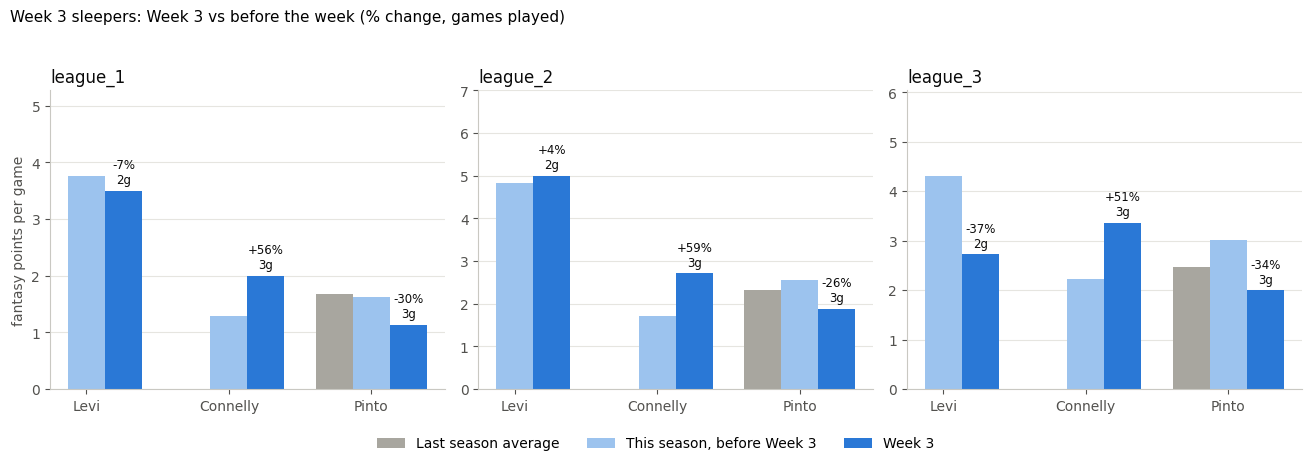

Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Loading game log for 8484803, 20262027 from cache, 0.0 hours old
Loading game log for 8481596, 20262027 from cache, 0.0 hours old


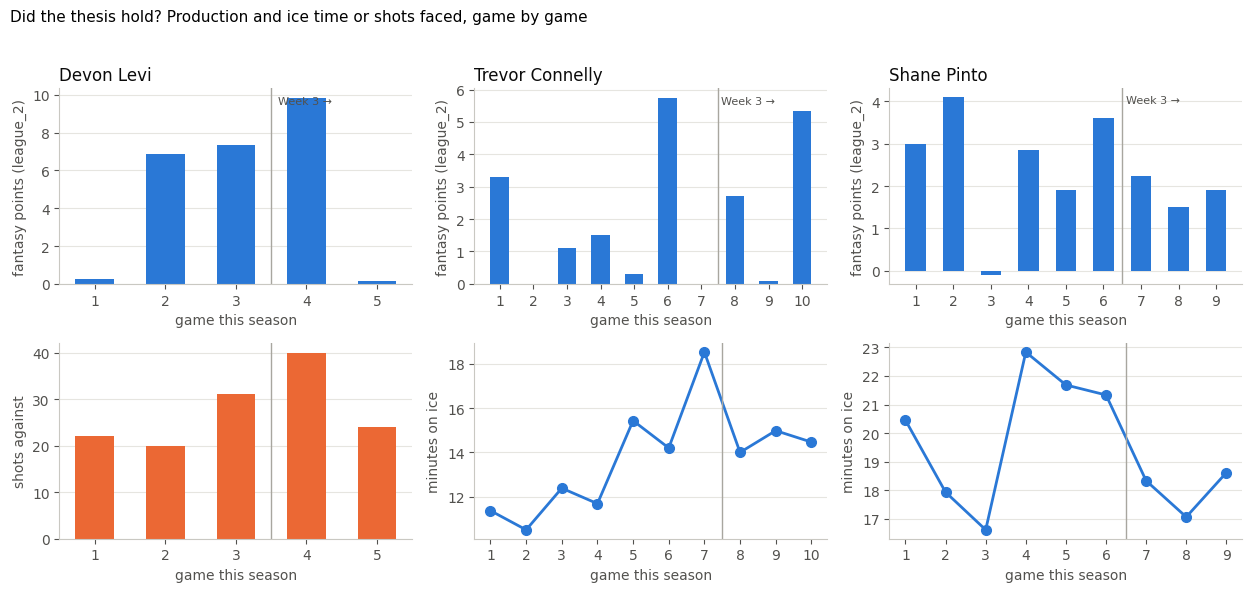

In [11]:
LIGHT = "#9cc3ee"

def plot_sleeper_recap_w3(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.4 * len(leagues), 4.6))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.26
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x, d["pre_week_avg"], w, color=LIGHT, label="This season, before Week 3")
        ax.bar(x + w, d["week3_avg"], w, color=BLUE, label="Week 3")
        top = np.nanmax(d[["last_season_avg", "pre_week_avg", "week3_avg"]].values)
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.notna(r["week3_avg"]):
                lab = f"{r['vs_pre_week']:+.0%}\n{int(r['week3_games'])}g" if pd.notna(r["vs_pre_week"]) else f"{int(r['week3_games'])}g"
                ax.text(xi + w, r["week3_avg"] + top * 0.02, lab, ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False)
    fig.suptitle("Week 3 sleepers: Week 3 vs before the week (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.show()

plot_sleeper_recap_w3(sleepers_w3_recap)

def plot_sleeper_games_w3r(league="league_2"):
    n = len(SLEEPERS_W3)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W3):
        pos = SLEEPER_POSITION.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur[cur["gameDate"] <= pd.Timestamp(WEEK3["league_1"][1])].reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        split = int((cur["gameDate"] < pd.Timestamp(WEEK3["league_1"][0])).sum()) + 0.5
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        ax.axvline(split, color=GRAY, linewidth=1)
        ax.text(split + 0.1, ax.get_ylim()[1] * 0.92, "Week 3 →", color=MUTED, fontsize=8)
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        ax.set_ylabel(f"fantasy points ({league})"); ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against")
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice")
        ax2.axvline(split, color=GRAY, linewidth=1)
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Did the thesis hold? Production and ice time or shots faced, game by game", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w3r("league_2")

In [12]:
sleepers_w3_recap.to_csv("predictions/sleepers_week03_results.csv", index=False)
print("Saved predictions/sleepers_week03_results.csv")

Saved predictions/sleepers_week03_results.csv


### Week 3 sleepers, did the thesis show up?

Fantasy points per game in Week 3 (Tue-Sun) against the same player's season before the week, and against last season where there is a baseline:

| Player | Week 3 games | League 1 | League 2 | League 3 |
|---|---|---|---|---|
| Levi vs before Week 3 | 2 | -7% | +4% | -37% |
| Connelly vs before Week 3 | 3 | +56% | +59% | +51% |
| Pinto vs before Week 3 | 3 | -30% | -26% | -34% |
| Pinto vs last season | 3 | -32% | -19% | -19% |

Levi and Connelly had no NHL games last season, so there is no last-season comparison.

| Player | Period | Games | Detail |
|---|---|---|---|
| Levi | Before Week 3 | 3 | 3 starts of 5 team games (0.60), 3 wins, .860 Sv%, 3.33 GA/g |
| Levi | Week 3 | 2 | 2 starts of 3 team games (0.67), 1 win, .940 Sv%, 2.00 GA/g |
| Connelly | Before Week 3 | 7 | 0.57 pts/g, 2.14 shots/g, 13% shooting, 13.4 min |
| Connelly | Week 3 | 3 | 1.00 pts/g, 1.67 shots/g, 40% shooting, 14.5 min |
| Pinto | Before Week 3 | 6 | 0.83 pts/g, 1.67 shots/g, 10% shooting, 20.1 min |
| Pinto | Week 3 | 3 | 0.33 pts/g, 1.33 shots/g, 0% shooting, 18.0 min |
| Pinto | Last season | 72 | 0.64 pts/g, 2.18 shots/g, 15% shooting, 18.7 min |

Against the checks I wrote down before the games:
- **Levi's start share held.** He started 2 of Edmonton's 3 games (the check was 2 or more) and his save percentage recovered from .860 to .940. The model had assumed a 0.50 start share (1.5 expected starts), so his role was a little bigger than the default. Fantasy points were about flat, because he won only 1 of his 2 starts and wins are the biggest component.
- **Connelly's ice time did not stay above 15 minutes** (14.5). His fantasy points rose 51% to 59%, but that came from a 40% shooting percentage while shots fell from 2.14 to 1.67 per game. That is luck rather than a bigger role.
- **Pinto did not stay above last season.** His production was 19% to 32% below last season's in every league, and his ice time fell from 20.1 to 18.0 minutes, back close to last season's 18.7. The extra-ice-time thesis did not hold.

One of three theses held. That is three players and 2 to 3 games each, so it is a record of how the method does and not evidence about it. Two weeks of sleepers so far: Week 2 went 0 of 3 against the last-season baseline, and Week 3 went 1 of 3 on its own thesis. Levi's actual start share (3 of 5, then 2 of 3) is also the kind of case a start share that blends this season's starts would handle better, so it goes on the list of v2 candidates for the Week 6 review.

# Week 4 Predictions

Same model as before (v1). Each league has my lineup against the opponent's, and the probability is that my player outscores his over the week, scaled by team games (goalies by expected starts). Opponents were entered by hand, and my lineup is unchanged apart from the opponent changes. Three headline picks are chosen before the games: per-game and recent form must agree, no player counted twice, and one per league where possible.

In [13]:
matchups_w4 = {
        "league_1": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Tage Thompson"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Brock Nelson"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Matt Boldy"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Gavin Mckenna"},
        {"position": "RW", "me": "Cole Perfetti", "opponent": "William Nylander"},
        {"position": "RW", "me": "Alex Tuch", "opponent": "Alexis Lafreniere"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Cale Makar"},
        {"position": "D", "me": "Mackenzie Weegar", "opponent": "Matthew Schaefer"},
        {"position": "D", "me": "Noah Dobson", "opponent": "Vince Dunn"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Brandt Clarke"},
        {"position": "UTIL", "me": "Elias Pettersson", "opponent": "Emil Heineman"},
        {"position": "G", "me": "Jeremy Swayman", "opponent": "Karel Vejmelka"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Mackenzie Blackwood"},
    ],
    "league_2": [
        {"position": "C", "me": "Nathan MacKinnon", "opponent": "William Nylander"},
        {"position": "C", "me": "Sebastian Aho", "opponent": "Morgan Geekie"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Cole Perfetti"},
        {"position": "LW", "me": "Tim Stutzle", "opponent": "Andrei Svechnikov"},
        {"position": "RW", "me": "Matt Boldy", "opponent": "Alexis Lafreniere"},
        {"position": "RW", "me": "Drake Batherson", "opponent": "Connor Bedard"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Darren Raddysh"},
        {"position": "D", "me": "Jackson LaCombe", "opponent": "Mikhail Sergachev"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Noah Dobson"},
        {"position": "D", "me": "Charlie McAvoy", "opponent": "Matthew Schaefer"},
        {"position": "UTIL", "me": "Sam Reinhart", "opponent": "Connor McDavid"},
        {"position": "UTIL", "me": "Elias Pettersson", "opponent": "Jack Hughes"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Joel Hofer"},
        {"position": "G", "me": "Mackenzie Blackwood", "opponent": "Juuse Saros"},
    ],

    "league_3": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Sidney Crosby"},
        {"position": "C", "me": "Auston Matthews", "opponent": "Steven Stamkos"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Dylan Guenther"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Jason Robertson"},
        {"position": "LW", "me": "Clayton Keller", "opponent": "Artemi Panarin"},
        {"position": "LW", "me": "J.T. Miller", "opponent": "Taylor Hall"},
        {"position": "RW", "me": "Martin Necas", "opponent": "Artturi Lehkonen"},
        {"position": "RW", "me": "Sam Reinhart", "opponent": "David Pastrnak"},
        {"position": "RW", "me": "Will Cuylle", "opponent": "Evgeni Malkin"},
        {"position": "F", "me": "Alex Ovechkin", "opponent": "Patrick Kane"},
        {"position": "F", "me": "Tom Wilson", "opponent": "Brayden Point"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Miro Heiskanen"},
        {"position": "D", "me": "Mikhail Sergachev", "opponent": "John Carlson"},
        {"position": "D", "me": "Thomas Harley", "opponent": "Victor Hedman"},
        {"position": "D", "me": "Rasmus Andersson", "opponent": "Josh Morrissey"},
        {"position": "UTIL", "me": "Brock Nelson", "opponent": "Mikko Rantanen"},
        {"position": "G", "me": "Karel Vejmelka", "opponent": "Sergei Bobrovsky"},
        {"position": "G", "me": "Linus Ullmark", "opponent": "Jake Oettinger"},
    ],
}

In [16]:
# Only needed when the automatic team lookup gets someone wrong, name -> NHL team abbreviation
TEAM_OVERRIDES = {
    # "Some Player": "TOR",
}

# Only needed to override the automatic goalie start-share, name -> share of team games he starts (0 to 1)
GOALIE_START_SHARE = {
    # "Devon Levi": 0.6,
}

def current_team(player):
    """Most recent team from the game log, this season first, then last season. Returns (team, source)."""
    if player in TEAM_OVERRIDES:
        return TEAM_OVERRIDES[player], "override"
    pid = resolve_id(player)
    for season, source in ((SEASON, "this season"), (PRIOR_SEASON, "last season, VERIFY")):
        log = get_game_log(pid, season=season)
        if not log.empty and "teamAbbrev" in log.columns:
            return log.sort_values("gameDate").iloc[-1]["teamAbbrev"], source
    return None, "not found"

def goalie_start_share(player):
    """Share of his team's games a goalie starts, from last season's starts out of 82, unless overridden."""
    if player in GOALIE_START_SHARE:
        return GOALIE_START_SHARE[player]
    log = get_game_log(resolve_id(player), season=PRIOR_SEASON)
    if log.empty or len(log) < 20 or "gamesStarted" not in log.columns:
        return 0.5
    starts = pd.to_numeric(log["gamesStarted"], errors="coerce").fillna(0).sum()
    return float(min(max(starts / 82, 0.15), 0.95))

def is_placeholder(value):
    return isinstance(value, str) and (value.startswith("None") or "suspended" in value.lower())

def run_weekly_comparisons(league):
    start, end = WEEK4[league]
    results = []
    for m in matchups_w4[league]:
        pos = m["position"]
        base = {"week": 4, "league": league, "position": pos, "me": m["me"], "opponent": m["opponent"]}

        if is_placeholder(m["me"]) or is_placeholder(m["opponent"]):
            results.append({**base, "note": "no real comparison in this slot"})
            continue

        cfg, fmap = cfg_and_map(league, pos)
        me_id, opp_id = resolve_id(m["me"]), resolve_id(m["opponent"])
        me_est = get_player_estimates(me_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        opp_est = get_player_estimates(opp_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        if me_est is None or opp_est is None:
            results.append({**base, "note": f"skipped (no data: me={me_est is not None}, opp={opp_est is not None})"})
            continue

        me_team, me_src = current_team(m["me"])
        opp_team, opp_src = current_team(m["opponent"])
        if me_team is None or opp_team is None:
            results.append({**base, "note": "skipped (could not find a team, add a TEAM_OVERRIDES entry)"})
            continue

        me_games = len(get_games_in_window(me_team, start, end))
        opp_games = len(get_games_in_window(opp_team, start, end))
        me_share = goalie_start_share(m["me"]) if pos == "G" else 1.0
        opp_share = goalie_start_share(m["opponent"]) if pos == "G" else 1.0

        kwargs = dict(label_a=str(m["me"]), label_b=str(m["opponent"]), start_share_a=me_share, start_share_b=opp_share)
        weekly = compare_weekly(me_est, me_games, opp_est, opp_games, use="season", **kwargs)
        weekly_recent = compare_weekly(me_est, me_games, opp_est, opp_games, use="recent", **kwargs)
        per_game = compare_players(me_est, opp_est, str(m["me"]), str(m["opponent"]))

        p = weekly["probability_a_outperforms_b"]
        notes = []
        if "VERIFY" in me_src or "VERIFY" in opp_src:
            notes.append("team taken from last season, verify")
        if me_games == 0 or opp_games == 0:
            notes.append("a player has no games this week")
        results.append({
            **base,
            "me_team": me_team, "opp_team": opp_team,
            "me_games": me_games, "opp_games": opp_games,
            "me_start_share": me_share if pos == "G" else np.nan,
            "opp_start_share": opp_share if pos == "G" else np.nan,
            "me_week_mu": weekly["mu_a"], "opp_week_mu": weekly["mu_b"],
            "me_week_sigma": weekly["sigma_a"], "opp_week_sigma": weekly["sigma_b"],
            "p_me_outperforms": p,
            "confidence": max(p, 1 - p),
            "favored": "me" if p > 0.5 else ("opponent" if p < 0.5 else "even"),
            "p_per_game": per_game["probability_a_outperforms_b"],
            "p_recent_form": weekly_recent["probability_a_outperforms_b"],
            "me_games_so_far": me_est["games_played"], "opp_games_so_far": opp_est["games_played"],
            "low_confidence": bool(me_est["low_confidence"] or opp_est["low_confidence"]),
            "prediction_unit": "weekly_total",
            "model_version": "v1",
            "headline_pick": np.nan,
            "note": "; ".join(notes),
        })
    return pd.DataFrame(results)

active = [lg for lg, ms in matchups_w4.items() if ms]
print("Leagues with matchups:", active or "none yet, paste matchups above and re-run")
week4_results = {lg: run_weekly_comparisons(lg) for lg in active}

Leagues with matchups: ['league_1', 'league_2', 'league_3']
Matched 'Tage Thompson' to 'Tage Thompson'
Loading game log for 8478402, 20262027 from cache, 0.4 hours old
Pulling fresh game log for 8478402, 20252026
Pulling fresh game log for 8479420, 20262027
Pulling fresh game log for 8479420, 20252026
Loading game log for 8478402, 20262027 from cache, 0.5 hours old
Loading game log for 8479420, 20262027 from cache, 0.0 hours old
Loading game log for 8482116, 20262027 from cache, 0.5 hours old
Pulling fresh game log for 8482116, 20252026
Loading game log for 8475754, 20262027 from cache, 0.5 hours old
Pulling fresh game log for 8475754, 20252026
Loading game log for 8482116, 20262027 from cache, 0.5 hours old
Loading game log for 8475754, 20262027 from cache, 0.5 hours old
Loading game log for 8476887, 20262027 from cache, 0.5 hours old
Pulling fresh game log for 8476887, 20252026
Loading game log for 8481557, 20262027 from cache, 0.5 hours old
Pulling fresh game log for 8481557, 202520

In [17]:
all_w4 = pd.concat(week4_results.values(), ignore_index=True)
show = ["position", "me", "opponent", "me_games", "opp_games", "me_week_mu", "opp_week_mu",
        "p_me_outperforms", "p_per_game", "p_recent_form", "low_confidence", "note"]
for league, df in week4_results.items():
    print(f"\n=== {league.upper()} ===")
    d = df.copy()
    for c in ("p_me_outperforms", "p_per_game", "p_recent_form"):
        if c in d:
            d[c] = d[c].map(lambda p: f"{p:.1%}" if pd.notna(p) else "n/a")
    print(d[[c for c in show if c in d.columns]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

print()
for league, df in week4_results.items():
    d = df[df["p_me_outperforms"].notna()]
    if d.empty:
        continue
    print(f"{league}: favored in {int((d['favored'] == 'me').sum())} of {len(d)} comparable slots, "
          f"{d['p_me_outperforms'].mean():.1%} average win probability across slots")
    for r in d[(d["p_me_outperforms"] - 0.5).abs() < 0.02].itertuples():
        print(f"   coin flip: {r.me} vs {r.opponent} ({r.p_me_outperforms:.1%})")
    for r in d[d["me_games"] != d["opp_games"]].itertuples():
        print(f"   unequal games: {r.me} {r.me_games:.0f} vs {r.opponent} {r.opp_games:.0f}")
    for r in df[df["p_me_outperforms"].isna()].itertuples():
        print(f"   {r.me} vs {r.opponent}: {r.note}")


=== LEAGUE_1 ===
position                 me            opponent  me_games  opp_games  me_week_mu  opp_week_mu p_me_outperforms p_per_game p_recent_form  low_confidence note
       C     Connor McDavid       Tage Thompson         3          2        10.8          4.6            90.3%      67.1%         92.8%           False     
       C        Tim Stutzle        Brock Nelson         3          4         8.1          7.2            57.1%      63.1%         63.7%           False     
      LW     Filip Forsberg          Matt Boldy         3          4         5.9          9.6            25.7%      44.1%         27.7%           False     
      LW        Kyle Connor       Gavin Mckenna         3          4         8.5          3.5            87.9%      79.7%         89.3%            True     
      RW      Cole Perfetti    William Nylander         3          4         5.5          9.1            24.8%      43.7%         28.9%           False     
      RW          Alex Tuch   Alexis Laf

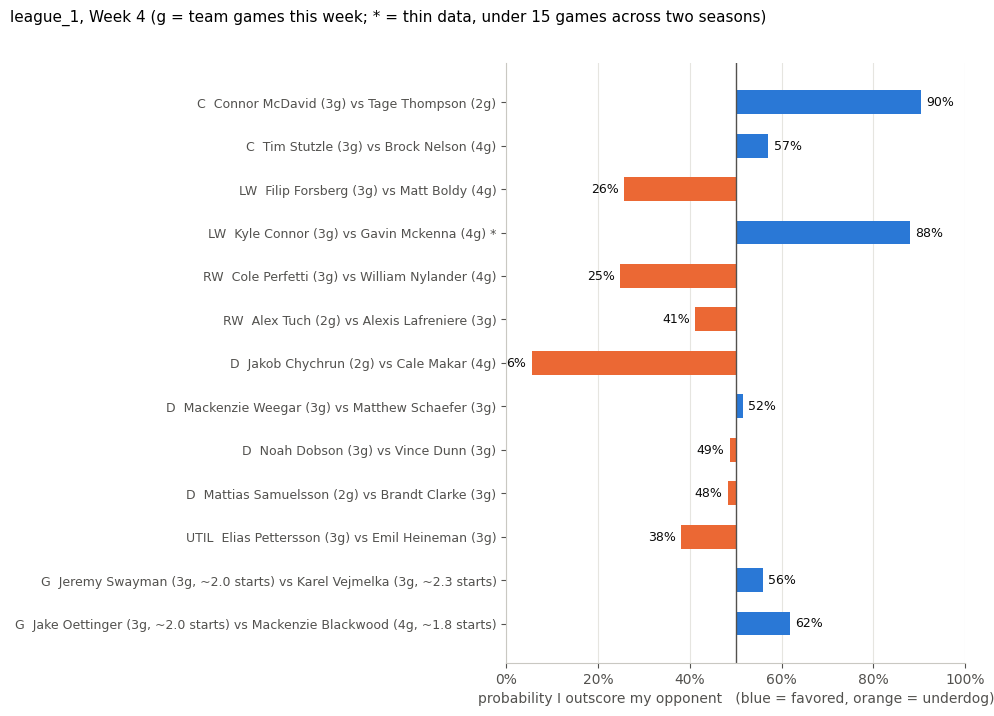

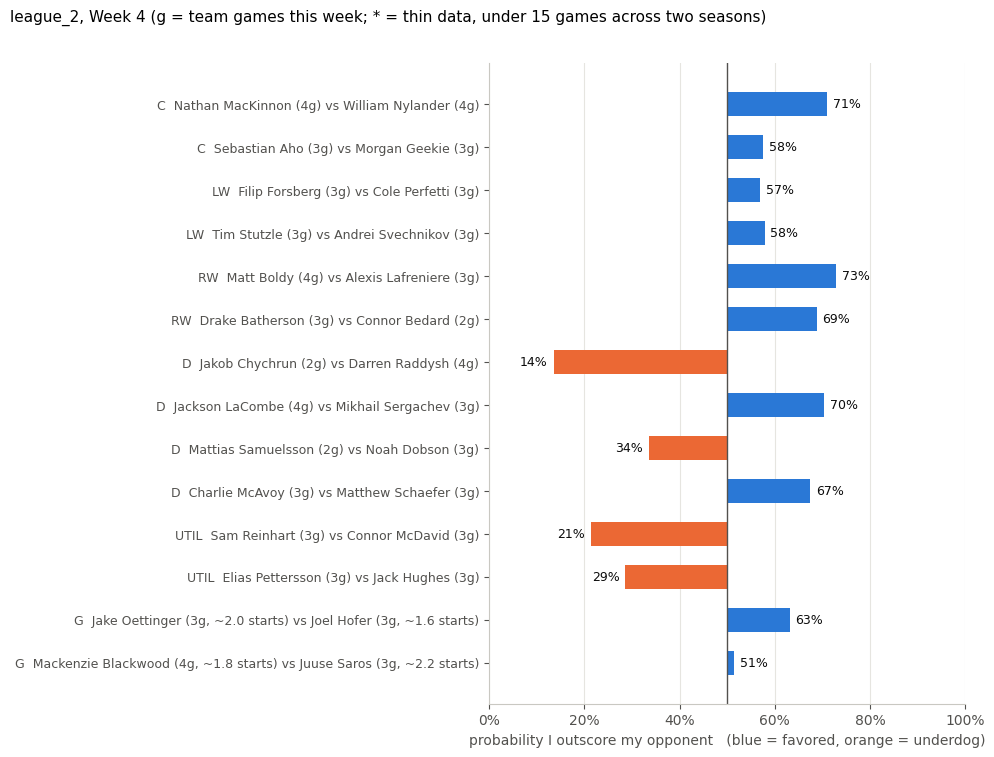

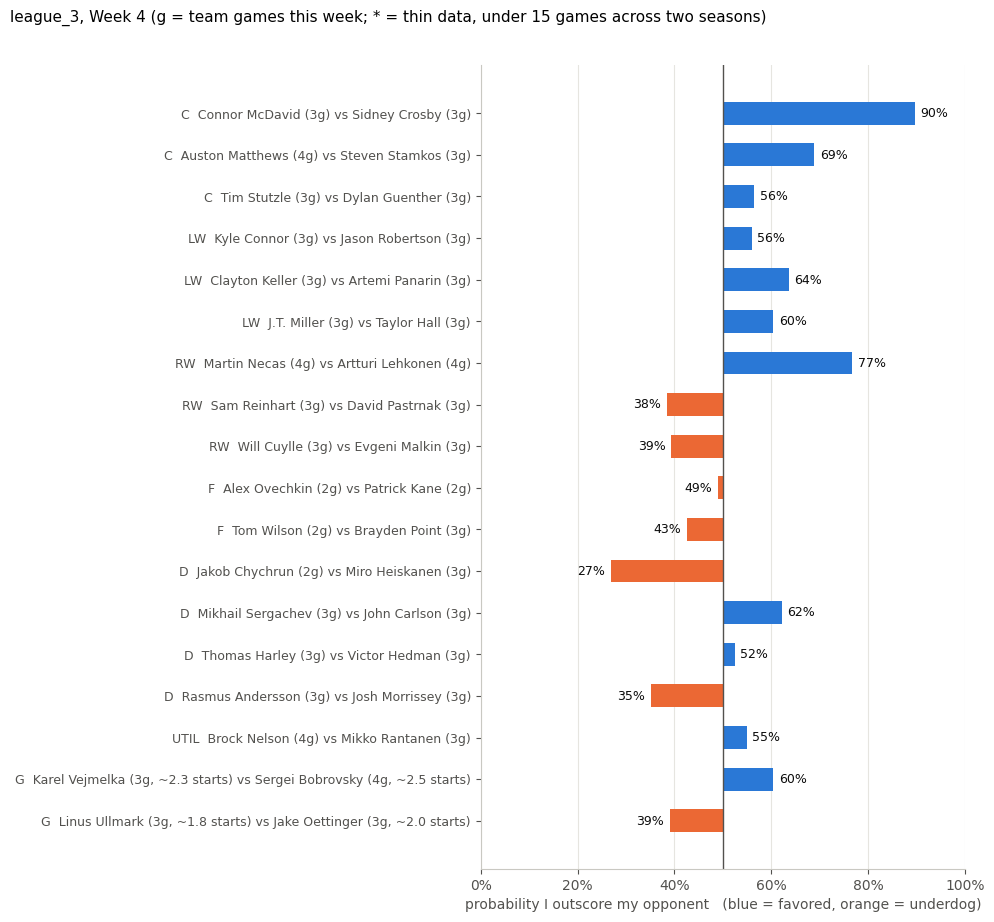

In [18]:
def plot_week4_bars(league, df):
    d = df[df["p_me_outperforms"].notna()].reset_index(drop=True)
    if d.empty:
        return
    y = np.arange(len(d))[::-1]
    colors = np.where(d["p_me_outperforms"] >= 0.5, BLUE, ORANGE)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    ax.barh(y, d["p_me_outperforms"] - 0.5, left=0.5, color=colors, height=0.55)
    ax.axvline(0.5, color=MUTED, linewidth=1)
    star = np.where(d["low_confidence"].astype(bool), " *", "")
    def side(name, games, share):
        # a goalie only starts some of his team's games, so show the expected starts too
        return f"{name} ({games:.0f}g)" if pd.isna(share) else f"{name} ({games:.0f}g, ~{games * share:.1f} starts)"
    labels = [f"{r.position}  {side(r.me, r.me_games, r.me_start_share)} vs {side(r.opponent, r.opp_games, r.opp_start_share)}{s}"
              for r, s in zip(d.itertuples(), star)]
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9)
    for yi, p in zip(y, d["p_me_outperforms"]):
        ax.text(p + (0.012 if p >= 0.5 else -0.012), yi, f"{p:.0%}", va="center",
                ha="left" if p >= 0.5 else "right", fontsize=9, color=INK)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("probability I outscore my opponent   (blue = favored, orange = underdog)")
    fig.suptitle(f"{league}, Week 4 (g = team games this week; * = thin data, under 15 games across two seasons)",
                 x=0.01, ha="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

for league, df in week4_results.items():
    plot_week4_bars(league, df)

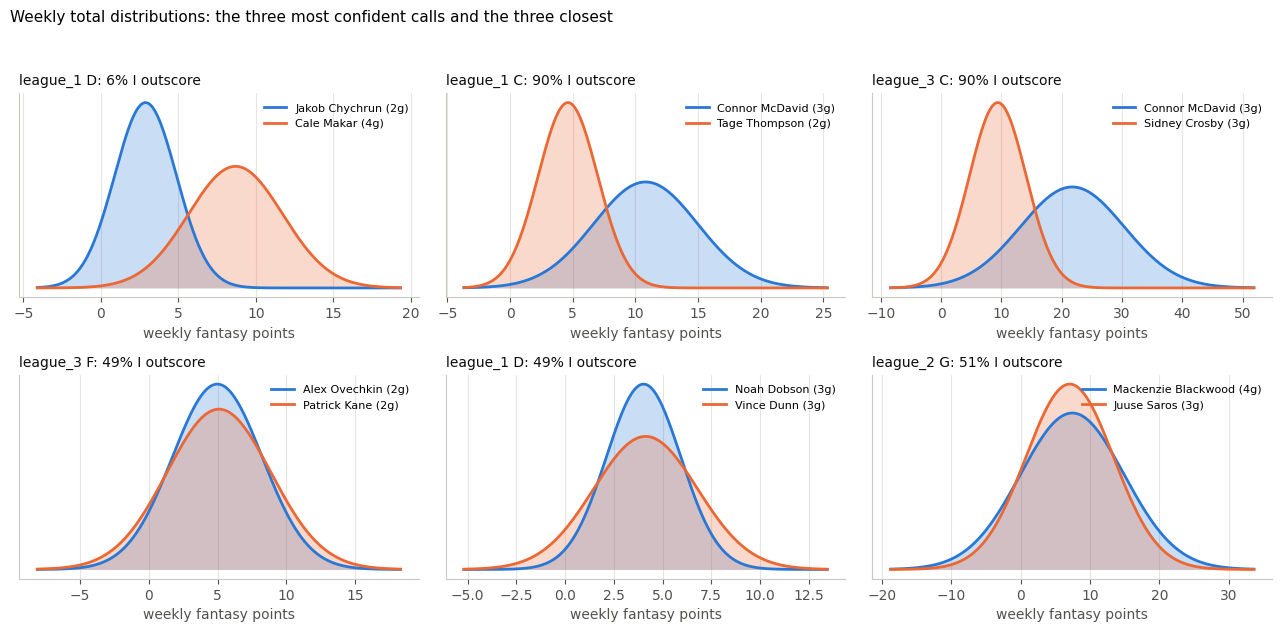

In [19]:
def plot_week4_distributions(all_df, n_each=3):
    ok = all_df[all_df["p_me_outperforms"].notna()]
    firm = ok.sort_values("confidence", ascending=False).head(n_each)
    close = ok.assign(gap=(ok["p_me_outperforms"] - 0.5).abs()).sort_values("gap").head(n_each)
    chosen = pd.concat([firm, close]).drop_duplicates(subset=["league", "me", "opponent"])
    n = len(chosen)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.3 * cols, 3.2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, r) in zip(axes, chosen.iterrows()):
        lo = min(r["me_week_mu"] - 3.5 * r["me_week_sigma"], r["opp_week_mu"] - 3.5 * r["opp_week_sigma"])
        hi = max(r["me_week_mu"] + 3.5 * r["me_week_sigma"], r["opp_week_mu"] + 3.5 * r["opp_week_sigma"])
        x = np.linspace(max(lo, 0) if lo > -1 else lo, hi, 400)
        ax.fill_between(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, linewidth=2, label=f"{r['me']} ({r['me_games']:.0f}g)")
        ax.fill_between(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, linewidth=2, label=f"{r['opponent']} ({r['opp_games']:.0f}g)")
        ax.set_title(f"{r['league']} {r['position']}: {r['p_me_outperforms']:.0%} I outscore", loc="left", fontsize=10)
        ax.set_yticks([])
        ax.set_xlabel("weekly fantasy points")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
        ax.grid(axis="y", visible=False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Weekly total distributions: the three most confident calls and the three closest", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

plot_week4_distributions(all_w4)

In [20]:
g = all_w4[(all_w4["position"] == "G") & all_w4["p_me_outperforms"].notna()].copy()
g["me_exp_starts"] = g["me_games"] * g["me_start_share"]
g["opp_exp_starts"] = g["opp_games"] * g["opp_start_share"]
cols = ["league", "me", "opponent", "me_games", "me_start_share", "me_exp_starts",
        "opp_games", "opp_start_share", "opp_exp_starts",
        "me_week_mu", "opp_week_mu", "p_me_outperforms", "p_per_game"]
print(g[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nstart_share = share of his team's games he's expected to start (last season's starts / 82 unless overridden)")
print("exp_starts = team games this week x start_share")

  league                  me            opponent  me_games  me_start_share  me_exp_starts  opp_games  opp_start_share  opp_exp_starts  me_week_mu  opp_week_mu  p_me_outperforms  p_per_game
league_1      Jeremy Swayman      Karel Vejmelka         3            0.66           1.98          3             0.77            2.30        8.11         6.65              0.56        0.58
league_1      Jake Oettinger Mackenzie Blackwood         3            0.66           1.98          4             0.44            1.76        8.57         5.45              0.62        0.57
league_2      Jake Oettinger          Joel Hofer         3            0.66           1.98          3             0.52            1.57       10.72         6.85              0.63        0.56
league_2 Mackenzie Blackwood         Juuse Saros         4            0.44           1.76          3             0.72            2.16        7.43         7.06              0.51        0.56
league_3      Karel Vejmelka    Sergei Bobrovsky       

**What stands out in Week 4:**
- I'm favored in 27 of 45 comparable slots: league 1 in 6 of 13 (49.0% average), league 2 in 10 of 14 (52.5%), league 3 in 11 of 18 (54.0%). League 1 is the one to watch, where the model favors my opponents more than my side.
- 20 of the 45 matchups have unequal games, mostly in league 1 (9 of 13). Several of the biggest calls come from the game count alone.
- Connor McDavid is 90% in both league 1 (3 games vs 2) and league 3 (3 vs 3). Kyle Connor is 88% against Gavin McKenna in league 1, but McKenna has thin data, so that estimate is the least reliable of the high-confidence calls.
- Jakob Chychrun is an underdog in all three leagues (6%, 14%, 27%) because his team has only 2 games. Alex Tuch, Alex Ovechkin, Tom Wilson and Connor Bedard also have 2-game weeks, so those are the calls most exposed to a wrong game count.
- Closest calls: Weegar vs Schaefer (51.5%), Dobson vs Dunn (48.8%), Samuelsson vs Clarke (48.2%), Blackwood vs Saros (51.5%) and Ovechkin vs Kane (49.1%).
- Goalies: expected starts run from about 1.6 (Hofer) to 2.5 (Bobrovsky). Blackwood is 4 team games at a 0.44 start share, so he's expected to start fewer games than Saros despite having more chances.
- The same players appear in several leagues (McDavid, Chychrun, Stutzle, Forsberg), so the 45 matchups are not 45 independent bets.

**Headline picks:**
- McDavid over Crosby (league 3, 90%): equal games, and per-game (77%) and recent form (93%) agree.
- MacKinnon over Nylander (league 2, 71%): equal games (4 vs 4), per-game 61%, recent form 65%.
- Makar over Chychrun (league 1, Chychrun 6%): mostly the schedule (4 games vs 2), with per-game at 36% and recent form at 3%.

In [22]:
import os
HEADLINE_PICKS = [
    ("league_3", "Connor McDavid", "Sidney Crosby"),      # 90%, equal games, per-game 77%, recent 93%
    ("league_2", "Nathan MacKinnon", "William Nylander"), # 71%, equal games (4v4), per-game 61%, recent 65%
    ("league_1", "Jakob Chychrun", "Cale Makar"),         # 6% (Makar favored), per-game 36%, recent 3%
]
assert len(HEADLINE_PICKS) == 3, "pick exactly three headline calls"

out = pd.concat(week4_results.values(), ignore_index=True)
out["headline_pick"] = False
for lg, me, opp in HEADLINE_PICKS:
    mask = (out["league"] == lg) & (out["me"] == me) & (out["opponent"] == opp)
    assert mask.sum() == 1, f"headline pick not found: {lg} {me} vs {opp}"
    out.loc[mask, "headline_pick"] = True
out["window_start"], out["window_end"] = WEEK4["league_1"]
out["late_start"] = False
out["source"] = "model_v1"
os.makedirs("predictions", exist_ok=True)
out.to_csv("predictions/week04.csv", index=False)
print(out.shape, out["headline_pick"].sum(), "headline picks")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/week04.csv")
except ImportError:
    pass

(45, 31) 3 headline picks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Week 4 sleepers

Three low-rostered skaters, chosen before the games. The process numbers (shots, ice time) matter more than their points so far.

| Player | Team | Games this week | Rostered | Thesis |
|---|---|---|---|---|
| Adam Edstrom | NSH | 3 | 8% | The 4 goals are a 27% shooting streak and won't last, but ice time and shots are up and he's above last season's average in all 8 games. |
| Michael Brandsegg-Nygard | DET | 3 | 14% | Shots nearly doubled and ice time is up at a normal 9% shooting rate, but about half his points came in two games, so expect spiky weeks. |
| Boone Jenner | WSH | 2 | 17% | Not a breakout: points per game match last season, but shots are up about 40%. Only 2 team games this week. |

In [25]:
SLEEPERS_W4 = ["Adam Edstrom", "Michael Brandsegg-Nygard", "Boone Jenner"]
SLEEPER_POSITION_W4 = {}   # all skaters
ROSTERED_W4 = {"Adam Edstrom": 0.08, "Michael Brandsegg-Nygard": 0.14, "Boone Jenner": 0.17}   # fill in Edstrom from Yahoo
SEASON_START, TODAY = "2026-09-01", "2026-10-18"

In [31]:
SLEEPER_THESIS_W4 = {
    "Adam Edstrom": "The 4 goals are a 27% shooting streak and won't last, but his ice time and shots are up and above last season's average in all 8 games, so the role is real.",
    "Michael Brandsegg-Nygard": "Shots nearly doubled and ice time is up, with a normal 9% shooting rate, so the role is real, but about half his points came in two games, so expect spiky weeks.",
    "Boone Jenner": "Not a breakout: points per game match last season, but shots are up about 40% at the same ice time, which should offset some goal regression.",
}

In [27]:
rows = []
for name in SLEEPERS_W4:
    pos = SLEEPER_POSITION_W4.get(name, "F")
    pid = resolve_id(name)
    team, src = current_team(name)
    team_games = len(get_games_in_window(team, *WEEK4["league_1"])) if team else np.nan
    share = goalie_start_share(name) if pos == "G" else np.nan
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        now = window_stats(name, pos, league, SEASON_START, TODAY)
        avg = now["total"] / now["games"] if now["games"] else np.nan
        prior_mu, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        est = get_player_estimates(pid, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        rows.append({
            "player": name, "pos": pos, "team": team, "league": league, "rostered": ROSTERED_W4.get(name),
            "games": now["games"], "this_season_avg": avg, "last_season_avg": prior_mu,
            "vs_last_season": (avg / prior_mu - 1) if prior_mu and not pd.isna(avg) else np.nan,
            "season_mu": est["season_mu"] if est else np.nan,
            "recent_mu": est["recent_mu"] if est else np.nan,
            "week4_team_games": team_games, "start_share": share,
            "exp_games_week4": team_games * share if pos == "G" else team_games,
            "low_confidence": est["low_confidence"] if est else np.nan,
        })
sleepers_w4 = pd.DataFrame(rows)
print(sleepers_w4.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nseason_mu = this season's games blended toward last season (what the predictions use)")
print("recent_mu = recent form across last season into this one;  exp_games_week4 for a goalie = team games x start share")

Matched 'Adam Edstrom' to 'Adam Edstrom'
Pulling fresh game log for 8481726, 20262027
Pulling fresh game log for 8481726, 20262027
Pulling fresh game log for 8481726, 20252026
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Pulling fresh game log for 8481726, 20262027
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Pulling fresh game log for 8481726, 20262027
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Matched 'Michael Brandsegg-Nygard' to 'Michael Brandsegg-Nygård'
Pulling fresh game log for 8484794, 20262027
Pulling fresh game log for 8484794, 20262027
Pulling fresh game log for 8484794, 20252026
Loading game l

In [28]:
skater_rows, goalie_rows = [], []
for name in SLEEPERS_W4:
    for label, season, s, e in (("This season", SEASON, SEASON_START, TODAY), ("Last season", PRIOR_SEASON, None, None)):
        if SLEEPER_POSITION_W4.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w4 = pd.DataFrame(skater_rows)
sleepers_goalie_w4 = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w4.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalies (start_share = starts / his team's games):")
print(sleepers_goalie_w4.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nA hot start built on shots and ice time tends to last. One built on a high shooting % usually doesn't.")

Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20252026 from cache, 0.0 hours old
Loading game log for 8476432, 20262027 from cache, 0.0 hours old
Loading game log for 8476432, 20252026 from cache, 0.0 hours old
Skaters:
                  player      period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
            Adam Edstrom This season      8          0.50            1.88          0.27         13.70
            Adam Edstrom Last season     35          0.14            0.89          0.10          9.46
Michael Brandsegg-Nygard This season      8          0.75            2.75          0.09         15.30
Michael Brandsegg-Nygard Last season     14          0.07            1.43          0.00         12.52
            Boone Jenner This season      8          0.62            2.75          0.18    

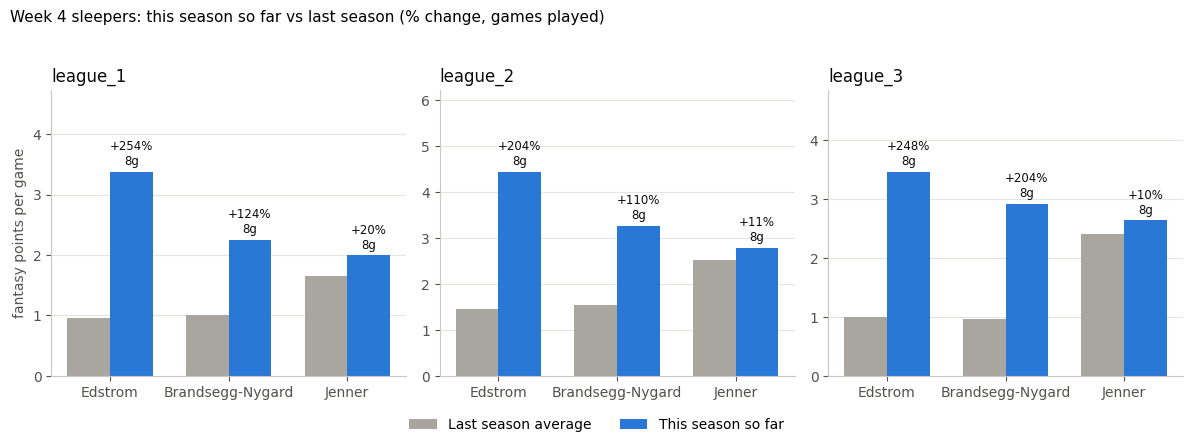

Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.0 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20252026 from cache, 0.0 hours old
Loading game log for 8476432, 20262027 from cache, 0.0 hours old
Loading game log for 8476432, 20252026 from cache, 0.0 hours old


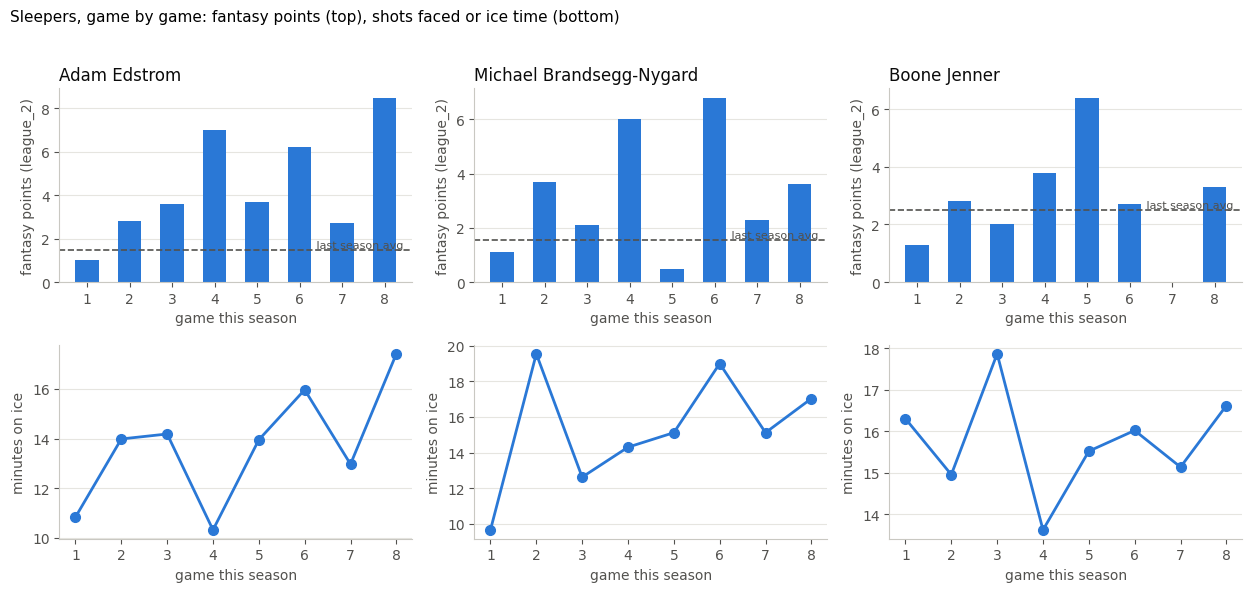

In [29]:
def plot_sleepers_w4(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.0 * len(leagues), 4.4))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.36
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w/2, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x + w/2, d["this_season_avg"], w, color=BLUE, label="This season so far")
        top = np.nanmax([d["last_season_avg"].max(), d["this_season_avg"].max()])
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.isna(r["this_season_avg"]):
                continue
            lab = (f"{r['vs_last_season']:+.0%}\n{int(r['games'])}g" if pd.notna(r["vs_last_season"])
                   else f"{int(r['games'])}g\nno prior\nNHL games")
            ax.text(xi + w/2, r["this_season_avg"] + top * 0.02, lab, ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Week 4 sleepers: this season so far vs last season (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.06, 1, 0.95)); plt.show()

plot_sleepers_w4(sleepers_w4)

def plot_sleeper_games_w4(league="league_2"):
    n = len(SLEEPERS_W4)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W4):
        pos = SLEEPER_POSITION_W4.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        last_avg = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)[0]
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur.reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        if last_avg:
            ax.axhline(last_avg, color=MUTED, linestyle="--", linewidth=1.2)
            ax.text(g[-1] + 0.45, last_avg, " last season avg", color=MUTED, fontsize=8, va="bottom", ha="right")
        else:
            ax.text(0.98, 0.95, "no prior NHL games", transform=ax.transAxes, color=MUTED, fontsize=8, ha="right", va="top")
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        ax.set_ylabel(f"fantasy points ({league})"); ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against")
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice")
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Sleepers, game by game: fantasy points (top), shots faced or ice time (bottom)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w4("league_2")

In [32]:
assert all(SLEEPER_THESIS_W4.values()), "write a thesis for every sleeper before saving"
sl_out = sleepers_w4.copy()
sl_out["week"] = 4
sl_out["thesis"] = sl_out["player"].map(SLEEPER_THESIS_W4)
sl_out["window_start"], sl_out["window_end"] = WEEK4["league_1"]
sl_out.to_csv("predictions/sleepers_week04.csv", index=False)
pd.concat([sleepers_process_w4.assign(kind="skater"), sleepers_goalie_w4.assign(kind="goalie")], ignore_index=True) \
  .to_csv("predictions/sleepers_week04_process.csv", index=False)
print("Saved sleepers_week04.csv and sleepers_week04_process.csv")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/sleepers_week04.csv")
    files.download("predictions/sleepers_week04_process.csv")
except ImportError:
    pass

Saved sleepers_week04.csv and sleepers_week04_process.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>